# 5. Global sensitivity analysis

The paper's figures use one parameter point. This notebook asks which parameters decide whether the
aggregate system produces a hype cycle, and where in parameter space cycles occur. Eleven factors vary
jointly over the ranges below; every other setting is as in the paper (media bump centred at $t=2$, message
ramp to its level $w$ by $t=2$, $P=1$, $b=10^{-3}$, horizon $T=30$).

**Outcomes.** Each run is classified by the path of expectations $m_1(t)$:

* *no overshoot*: expectations never fall by 0.02 or more after an interior peak;
* *overshoot, no recovery*: they peak, fall and settle (a hype–disappointment curve);
* *hype cycle*: they peak, fall by at least 0.02 and recover by at least 0.01.

Continuous outcomes are the drop from peak to trough of $m_1$ and adoption $\rho_2$ at $T=30$.

**Method.** Variance-based (Sobol) indices from a Saltelli design with $n=2048$ base points from a scrambled
Sobol sequence, $n(d+2)=26{,}624$ runs (Saltelli et al. 2010, *Computer Physics Communications* 181, 259–270).
The first-order index $S_i$ is the share of output variance explained by factor $i$ alone; the total index
$S_{T,i}$ adds all its interactions. A large gap between the two means the factor matters through
interactions. Intervals are bootstrap 95%. For the 0/1 outcomes the indices decompose the variance of the
indicator, i.e. of the probability of that pattern.

Runs come from `scripts/run_sensitivity.py`; the estimators are tested against the analytic indices of the
Ishigami function in `tests/test_sensitivity.py`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import NullFormatter

from kinetic_hype import sensitivity as sa
from kinetic_hype.plotting import use_style, INK, INK_2

use_style()
RES = Path("..") / "results"
runs = pd.read_csv(RES / "sensitivity_runs.csv.gz")
idx = pd.read_csv(RES / "sensitivity_indices.csv")
LABEL = {f.name: f.label for f in sa.FACTORS}
pd.DataFrame([{"factor": f.label, "low": f.low, "high": f.high, "scale": "log" if f.log else "linear",
               "baseline": sa.BASELINE[f.name]} for f in sa.FACTORS])

,factor,low,high,scale,baseline
0,media width $\sigma^2_\mu$,0.5,32.0,log,2.0
1,media message $w$,0.8,2.0,linear,1.5
2,performance ceiling $r_\infty$,0.6,1.4,linear,0.8
3,investment on expectations $k_1$,0.1,2.0,log,0.5
4,investment on adoption $k_2$,0.1,2.0,log,0.5
5,exogenous investment slope,0.0,0.5,linear,0.1
6,self-reasoning variance $\gamma$,0.2,3.0,log,0.8
7,non-user influence $\alpha_1=a_1/b$,1.0,50.0,log,10.0
8,user influence $\alpha_2=a_2/b$,2.0,100.0,log,15.0
9,purchase rate $\lambda$,0.2,3.0,log,0.8


## How common is each pattern?

Using the two independent blocks of the design (4096 points drawn uniformly over the ranges):

In [2]:
base = runs[runs.block.isin(["A", "B"])].copy()
base["gap"] = base.w0 - base.r_inf
share = base.pattern.map(sa.PATTERNS).value_counts(normalize=True).reindex(list(sa.PATTERNS.values()))
print(share.round(3).to_string())
print(f"\nfailed runs: {runs.pattern.isna().sum()} of {len(runs)}")

pattern
no overshoot              0.508
overshoot, no recovery    0.339
hype cycle                0.153

failed runs: 0 of 26624


## Which factors matter?

outcome,any_overshoot,drop,hype_cycle,rho_T
factor,,,,
media_width2,0.03,0.02,0.33,0.00
w0,0.40,0.25,0.24,0.02
r_inf,0.65,0.45,0.55,0.87
k1,0.13,0.03,0.46,0.01
k2,0.03,0.00,0.05,0.00
inv_slope,0.08,0.02,0.27,0.01
gam,0.07,0.02,0.10,0.15
alpha1,0.06,0.02,0.10,0.07
alpha2,0.38,0.34,0.35,0.19


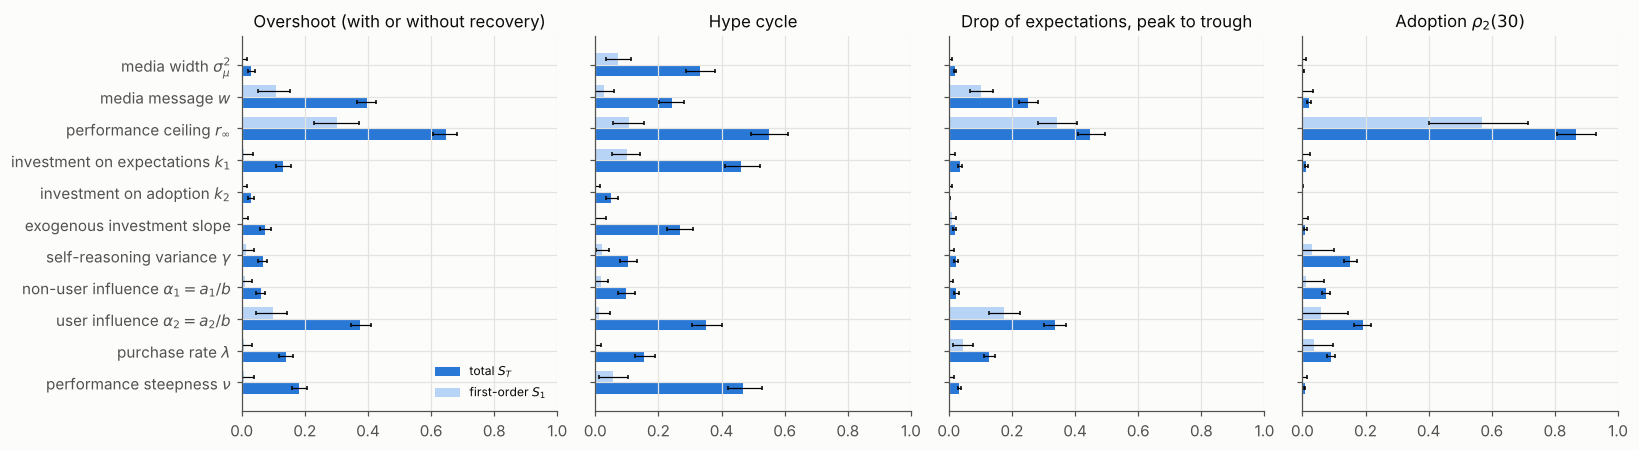

In [3]:
outs = [("any_overshoot", "Overshoot (with or without recovery)"), ("hype_cycle", "Hype cycle"),
        ("drop", "Drop of expectations, peak to trough"), ("rho_T", r"Adoption $\rho_2(30)$")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
order = [f.name for f in sa.FACTORS]
y = np.arange(len(order))
for ax, (o, title) in zip(axes, outs):
    d = idx[idx.outcome == o].set_index("factor").loc[order]
    ax.barh(y + 0.18, d.ST, height=0.36, color="#2a78d6", label="total $S_T$",
            xerr=[d.ST - d.ST_lo, d.ST_hi - d.ST], error_kw=dict(lw=0.8, capsize=1.5))
    ax.barh(y - 0.18, d.S1.clip(lower=0), height=0.36, color="#b7d3f6", label="first-order $S_1$",
            xerr=[(d.S1 - d.S1_lo).clip(lower=0), (d.S1_hi - d.S1).clip(lower=0)], error_kw=dict(lw=0.8, capsize=1.5))
    ax.set_title(title); ax.set_xlim(0, 1)
axes[0].set_yticks(y); axes[0].set_yticklabels([LABEL[n] for n in order]); axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
idx.pivot(index="factor", columns="outcome", values="ST").loc[order].round(2)

**Reading the indices.**

* **Whether expectations overshoot** is decided mainly by the performance ceiling $r_\infty$ ($S_T\approx0.65$),
  the media message $w$ (0.40) and the influence of users $\alpha_2$ (0.38), followed by the timing parameters
  $\nu$, $\lambda$ and $k_1$. The size of the drop depends on the same factors. The width of the media bump hardly
  matters for either ($S_T\le0.03$).
* **Whether the overshoot becomes a full cycle** (a trough below the eventual plateau, then recovery) depends
  on many factors at once: $r_\infty$ (0.55), $\nu$ (0.47), $k_1$ (0.46), $\alpha_2$ (0.35), the media width
  (0.33) and exogenous investment (0.27). Every first-order index is at most 0.11, so the cycle is produced by
  combinations of factors, not by any one of them.
* **Long-run adoption** is almost entirely set by $r_\infty$ (0.87), with a smaller role for $\alpha_2$ and the
  noise $\gamma$; the media signals do not affect it.
* $k_2$ (investment responding to adoption) matters little for any outcome ($S_T\le0.05$); $\alpha_1$ (influence
  among non-users) has a modest effect ($S_T\le0.10$), through the spread of perceived values rather than their mean.

## Where do cycles occur?

Share of each pattern conditional on one factor (10 equal-count bins), and on the gap between the media
message and the performance ceiling, $w-r_\infty$, which sets the sign of $A=b(w-r)$ in the analytical
conditions (Section 4.1 of the paper).

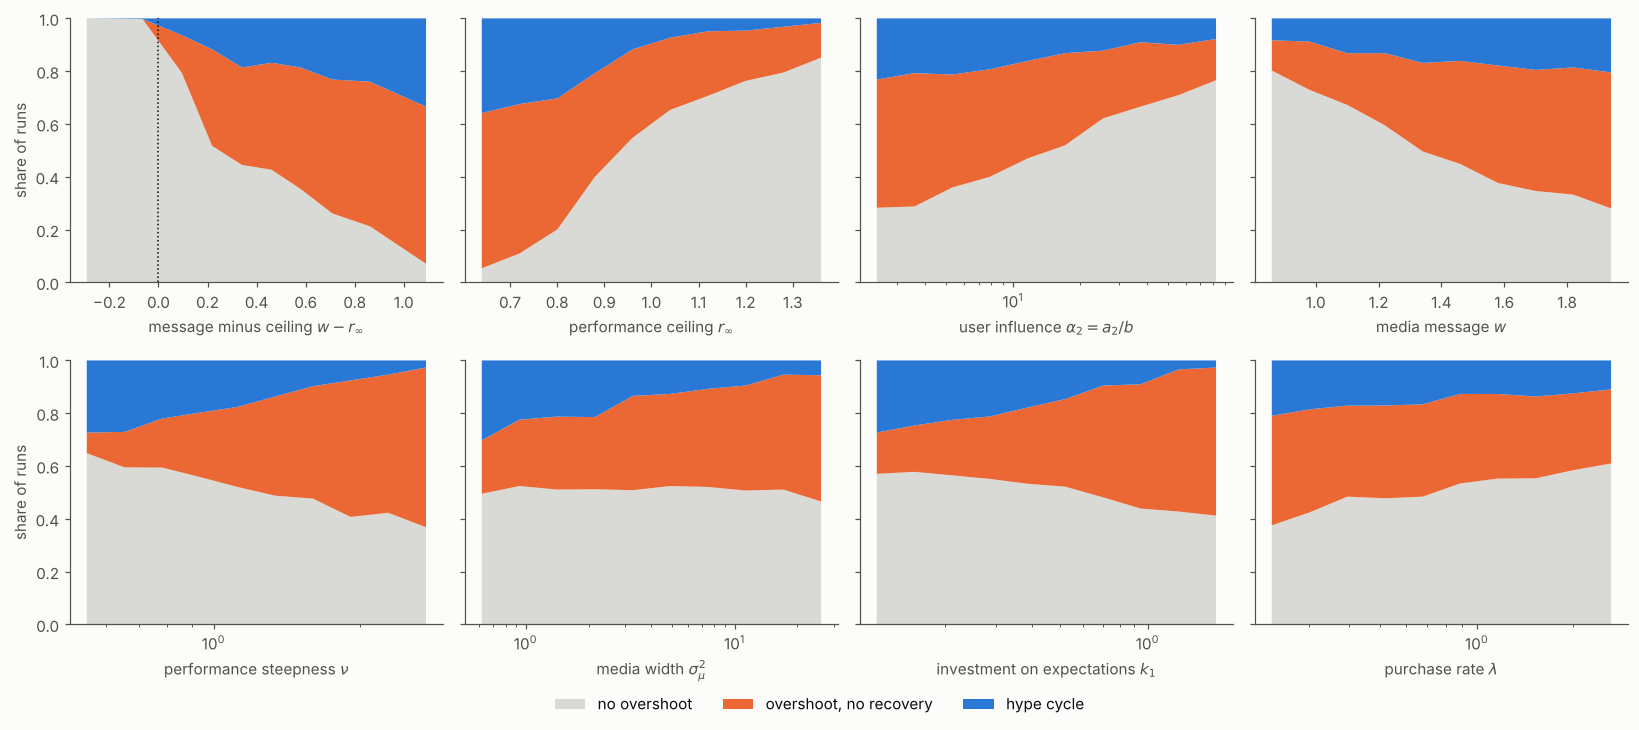

In [4]:
COL = {0: "#d9d9d6", 1: "#eb6834", 2: "#2a78d6"}
panels = ["gap", "r_inf", "alpha2", "w0", "nu", "media_width2", "k1", "lam"]
lab = {**LABEL, "gap": r"message minus ceiling $w-r_\infty$"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharey=True)
for ax, name in zip(axes.flat, panels):
    q = pd.qcut(base[name], 10, duplicates="drop")
    tab = pd.crosstab(q, base.pattern, normalize="index").reindex(columns=[0, 1, 2], fill_value=0)
    mid = base.groupby(q, observed=True)[name].median().to_numpy()
    ax.stackplot(mid, tab[0], tab[1], tab[2], colors=[COL[0], COL[1], COL[2]],
                 labels=list(sa.PATTERNS.values()))
    if name in ("media_width2", "k1", "alpha2", "lam", "nu"):
        ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter())
    if name == "gap":
        ax.axvline(0, color=INK, lw=1, ls=":")
    ax.set_xlabel(lab[name]); ax.set_ylim(0, 1); ax.grid(False)
axes[0, 0].set_ylabel("share of runs"); axes[1, 0].set_ylabel("share of runs")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()

In [5]:
tab = pd.crosstab(pd.cut(base.gap, [-1.0, -0.2, 0.0, 0.2, 0.5, 1.0, 1.5]), base.pattern.map(sa.PATTERNS),
                  normalize="index").reindex(columns=list(sa.PATTERNS.values()), fill_value=0).round(3)
tab["runs"] = pd.cut(base.gap, [-1.0, -0.2, 0.0, 0.2, 0.5, 1.0, 1.5]).value_counts().sort_index().to_numpy()
tab

pattern,no overshoot,"overshoot, no recovery",hype cycle,runs
gap,,,,
"(-1.0, -0.2]",1.000,0.000,0.000,336
"(-0.2, 0.0]",1.000,0.000,0.000,436
"(0.0, 0.2]",0.766,0.167,0.067,598
"(0.2, 0.5]",0.440,0.398,0.162,1018
"(0.5, 1.0]",0.282,0.492,0.226,1365
"(1.0, 1.5]",0.052,0.621,0.327,343


**What this says about the mechanism.**

* **Overshoot requires the media to promise more than the technology can deliver.** None of the 772 sampled
  points with $w\le r_\infty$ overshoots. The probability rises with the gap: about 23% for gaps up to 0.2, 56% for
  gaps of 0.2–0.5, and 95% above 1. This is the sign condition $A=b(w-r)>0$ of Section 4.1, now as a global
  result. It is necessary but not sufficient: credible users (high $\alpha_2$) and fast purchasing (high
  $\lambda$) bring users' reports in early and suppress the overshoot.
* **A trough below the plateau needs media attention to fade before performance catches up.** Among runs that
  overshoot, 31% produce a full cycle. Cycles become rarer as the media bump widens (26% of runs in the
  narrowest quarter against 6% in the widest), and as performance improves faster through $k_1$, $\nu$ or
  exogenous investment. With fast improvement, expectations glide down onto the plateau instead of undershooting
  it. This is the race described by the disillusionment condition (Eq. 23 of the paper), seen across the whole
  parameter space.

## Two-factor maps around the paper's baseline

Each map varies two factors on a $41\times41$ grid with the others at the baseline (marked with a cross). Colour
is the pattern; contours show the drop of expectations from peak to trough.

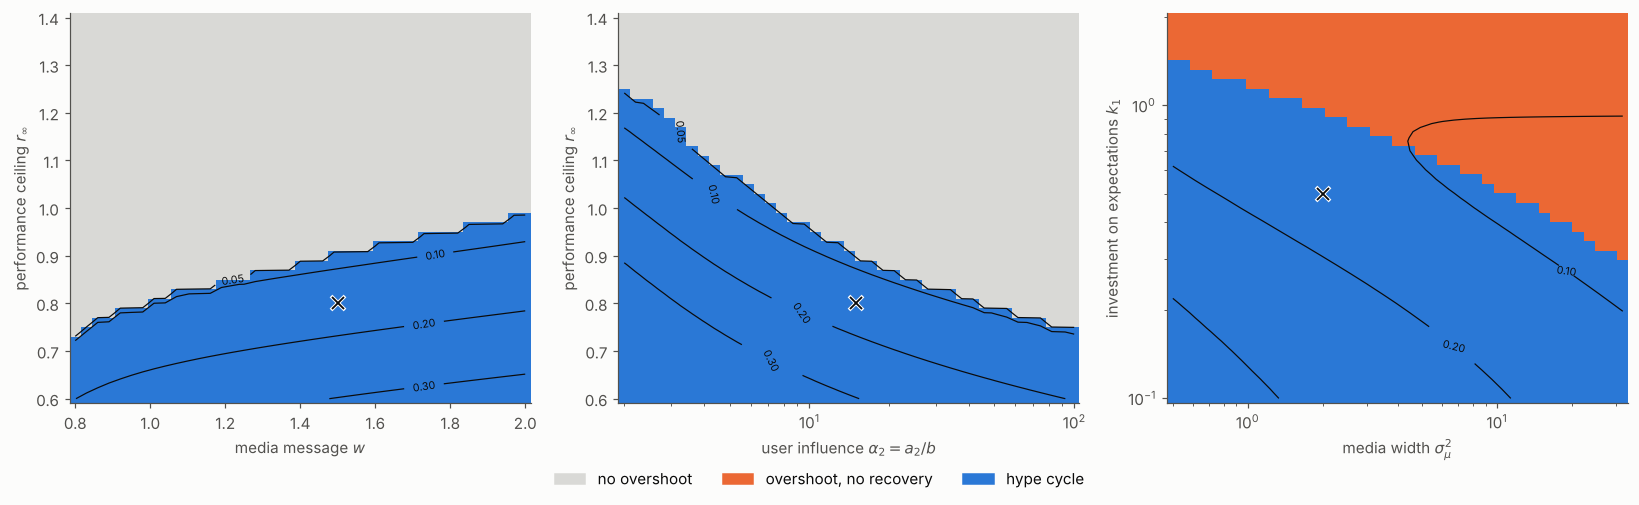

In [6]:
cmap = ListedColormap([COL[0], COL[1], COL[2]])
pairs = [("w0", "r_inf"), ("alpha2", "r_inf"), ("media_width2", "k1")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (a, b) in zip(axes, pairs):
    m = pd.read_csv(RES / f"sensitivity_map_{a}_{b}.csv")
    xa, xb = np.sort(m[a].unique()), np.sort(m[b].unique())
    Z = m.pivot(index=b, columns=a, values="pattern").loc[xb, xa].to_numpy()
    D = m.pivot(index=b, columns=a, values="drop").loc[xb, xa].to_numpy()
    ax.pcolormesh(xa, xb, Z, cmap=cmap, vmin=-0.5, vmax=2.5, shading="nearest")
    cs = ax.contour(xa, xb, D, levels=[0.05, 0.1, 0.2, 0.3], colors=INK, linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.2f")
    ax.plot(sa.BASELINE[a], sa.BASELINE[b], "x", color="white", ms=9, mew=2.5)
    ax.plot(sa.BASELINE[a], sa.BASELINE[b], "x", color=INK, ms=8, mew=1.2)
    for name, axis in ((a, "x"), (b, "y")):
        if {f.name: f for f in sa.FACTORS}[name].log:
            getattr(ax, f"set_{axis}scale")("log")
            getattr(ax, f"{axis}axis").set_minor_formatter(NullFormatter())
    ax.set_xlabel(LABEL[a]); ax.set_ylabel(LABEL[b]); ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[k]) for k in (0, 1, 2)]
fig.legend(handles, list(sa.PATTERNS.values()), loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.05))
fig.tight_layout()

**The paper's baseline lies inside the cycle region.** At $w=1.5$ cycles occur for performance ceilings up to
$r_\infty=0.90$ (baseline 0.8) and for user influence up to $\alpha_2\approx41$ (baseline 15). A larger message $w$
widens the region: the largest ceiling compatible with an overshoot rises from 0.80 at $w=1$ to 0.98 at $w=2$.
A slower-fading media campaign combined with strong expectation-driven investment ($k_1$) turns cycles into a
monotone decline to the plateau.

## Limits of this analysis

* It covers the aggregate (mean-field) system only. Notebook 4 shows that the agent-based model can behave
  differently when expectations form slowly.
* The ranges are judgement calls bracketing the paper's baseline; indices depend on them. Factors were drawn
  independently, so the sample includes points with $a_2<a_1$ (users less influential than non-users),
  which the paper's narrative excludes.
* The pattern thresholds (0.02 drop, 0.01 recovery) are arbitrary; the continuous drop is reported for that
  reason.
* Media timing and the message ramp are fixed; only the width of the media bump varies.